# 07 · Robustness — the headline under its own staleness controls

**Post-hoc robustness, not pre-registered.** Weeks 5–6 withdrew three regime effects as
staleness artifacts. This notebook puts the *headline level* (GG_cross) and the session null
through the same controls, measures how much of each "session" the liquid-hours window really
contains, and explains the day-level jumps in the basis. The Week-7 GBP replication,
news-window exclusion and full multiplicity ledger are still to come (see the end).

In [1]:
%load_ext autoreload
%autoreload 2
import datetime as dt, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fxpd.config import TRIANGLES, OUTPUTS_DIR, ensure_dirs
from fxpd.calendar.sessions import label_sessions
from fxpd.calendar import value_dates as vd
from fxpd.data.processed import get_panel
from fxpd.econo import discovery as disc, vecm
from fxpd.econo.hy import sign_test
from fxpd.inference import bootstrap as bs
ensure_dirs(); warnings.simplefilter("ignore")
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

## Parameters — tweak these

In [2]:
TRIANGLE = "majors"
START, END = dt.date(2025, 12, 15), dt.date(2026, 7, 20)
K, LIQUID, LIQUID_WIDE = 10, (7, 17), (7, 20)
SESSIONS = ["TOK", "TOK+LDN", "LDN", "LDN+NY", "NY"]
BLOCK, B, DELTA = 5, 2000, 0.05          # day-block bootstrap; TOST equivalence margin
OFFSET_BP = 0.15                         # |day-mean z| above this = a level-shifted day
tri = TRIANGLES[TRIANGLE]
dates = list(pd.bdate_range(START, END).date)
print(f"{tri} | {len(dates)} business days | 1s grid, k={K}, liquid {LIQUID} UTC")

Triangle(name='majors', cross='EURJPY', leg1='EURUSD', leg2='USDJPY') | 156 business days | 1s grid, k=10, liquid (7, 17) UTC


## 1 · The headline under three clocks

Same spec as 03 (1 s, k=10, liquid hours), estimated (a) on every grid bar, (b) only on bars
where cross and synthetic were both fresh at t−1, (c) in refresh time (sample only when every
leg has updated). EURJPY ticks about as often as both dollar legs combined, so on a LOCF grid
the stale synthetic "catches up" after the fact — which the VECM reads as the synthetic
error-correcting, i.e. as the cross leading.

In [3]:
clocks = {
    "grid, all bars":   disc.fit_discovery_windows(tri, dates, "1s", K, liquid=LIQUID),
    "grid, fresh-only": disc.fit_discovery_windows(tri, dates, "1s", K, liquid=LIQUID,
                                                   stale_filter=True),
    "refresh time":     disc.fit_discovery_windows(tri, dates, "1s", K, liquid=LIQUID,
                                                   clock="refresh"),
}

def summary(r):
    a = disc.aggregate_discovery(r)
    v = r[r["valid"]]
    return {"GG_cross": a.loc["cross", "gg_median"],
            "IQR": f"[{a.loc['cross', 'gg_q25']:.3f}, {a.loc['cross', 'gg_q75']:.3f}]",
            "GG incl. out-of-[0,1]": a.attrs["gg_inclusive_median"],
            "share of windows > 0.5": float((v["gg_cross"] > 0.5).mean()),
            "HL dynamic (s)": a.attrs.get("half_life_dyn_median", np.nan),
            "median obs/window": float(r["n_obs"].median()),
            "valid/estimated": f"{a.attrs['n_valid']}/{a.attrs['n_windows']}",
            "days skipped": r.attrs["skipped"]}

HEAD = pd.DataFrame({k: summary(r) for k, r in clocks.items()}).T
HEAD

,GG_cross,IQR,"GG incl. out-of-[0,1]",share of windows > 0.5,HL dynamic (s),median obs/window,valid/estimated,days skipped
"grid, all bars",0.6521,"[0.583, 0.727]",0.6537,0.9272,8.187,3.599e+04,151/154,2
"grid, fresh-only",0.5872,"[0.504, 0.706]",0.5973,0.7534,5.962,1.188e+04,146/154,2
refresh time,0.5702,"[0.528, 0.616]",0.5702,0.8636,5.223,2.756e+04,154/154,2


,paired days,median diff,IQR,days lower,sign-test p
"vs grid, all bars",,,,,
"grid, fresh-only",146,-0.05027,"[-0.124, +0.006]",102,1.77e-06
refresh time,151,-0.08057,"[-0.153, -0.025]",126,2.04e-17


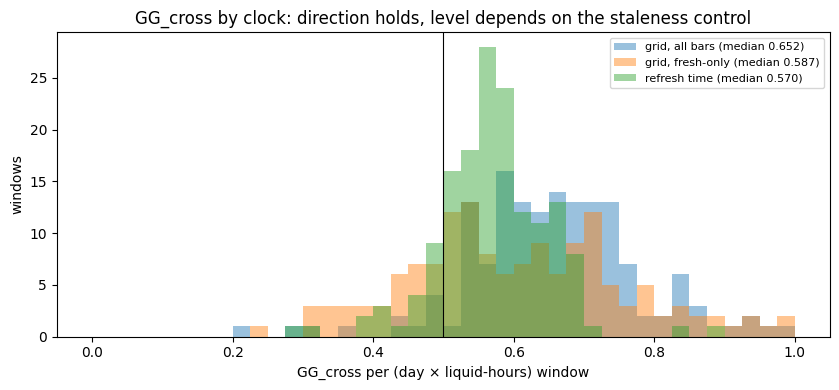

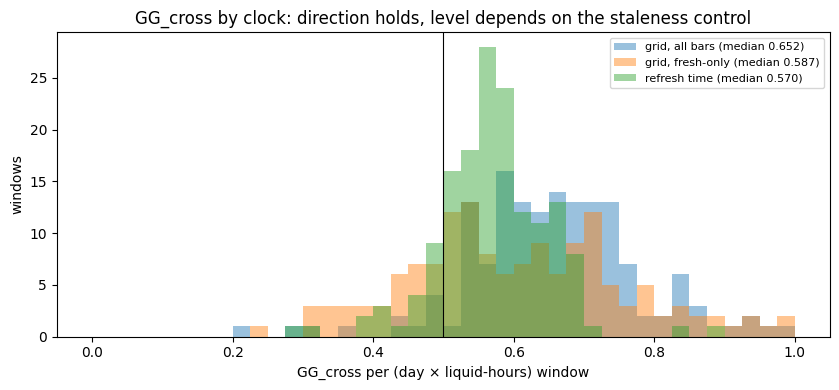

In [4]:
base = clocks["grid, all bars"].query("valid").set_index("date")["gg_cross"]
rows = []
for name in ["grid, fresh-only", "refresh time"]:
    alt = clocks[name].query("valid").set_index("date")["gg_cross"]
    d = (alt - base).dropna()
    st = sign_test(d)                                  # binomial sign test on "alt < grid"
    rows.append({"vs grid, all bars": name, "paired days": st["n"], "median diff": d.median(),
                 "IQR": f"[{d.quantile(.25):+.3f}, {d.quantile(.75):+.3f}]",
                 "days lower": st["k_neg"], "sign-test p": st["binom_p"]})
PAIRED = pd.DataFrame(rows).set_index("vs grid, all bars")
display(PAIRED)

fig, ax = plt.subplots(figsize=(8.5, 4))
bins = np.linspace(0, 1, 41)
for name, c in zip(clocks, ["tab:blue", "tab:orange", "tab:green"]):
    v = clocks[name].query("valid")["gg_cross"]
    ax.hist(v, bins=bins, alpha=0.45, color=c, label=f"{name} (median {v.median():.3f})")
ax.axvline(0.5, color="k", lw=0.8)
ax.set_xlabel("GG_cross per (day × liquid-hours) window"); ax.set_ylabel("windows")
ax.set_title("GG_cross by clock: direction holds, level depends on the staleness control")
ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(OUTPUTS_DIR / "07_headline_clocks.png", dpi=130)
fig

## 2 · Sessions under refresh time — does the null survive the correction?

05's pre-registered family (H1–H5) re-run on both clocks with the same day-block bootstrap.
`p_holm` adjusts within each clock (the grid rows reproduce 05); `p_holm_both_clocks` treats
all ten tests as one family. The refresh rows are post-hoc and outside 05's pre-registration.

In [5]:
res = {clock: {s: disc.fit_discovery_windows(tri, dates, "1s", K, liquid=LIQUID, session=s,
                                             clock=clock) for s in SESSIONS}
       for clock in ["grid", "refresh"]}

def sess_row(r):
    a = disc.aggregate_discovery(r)
    return [a.loc["cross", "gg_median"], a.attrs.get("half_life_dyn_median", np.nan),
            a.attrs["n_valid"]]

SESS = pd.concat({c: pd.DataFrame([sess_row(res[c][s]) for s in SESSIONS], index=SESSIONS,
                                  columns=["GG_cross", "HL_dyn_s", "n"]) for c in res}, axis=1)
SESS

grid                refresh              
        GG_cross HL_dyn_s    n GG_cross HL_dyn_s    n
TOK       0.6301    6.435   69   0.4779    2.744   73
TOK+LDN   0.6312    7.086  142   0.5359    3.462  153
LDN       0.6779    8.293  151   0.5813    5.694  154
LDN+NY    0.6508    7.186  145   0.5859    3.659  154
NY        0.6676    7.043  142   0.6122    3.118  135

In [6]:
def run_family(rs):
    wide_gg = bs.metric_by_day(rs, "gg_cross")
    wide_hl = bs.metric_by_day(rs, "half_life_dyn_s")
    wide_mid = bs.metric_by_day({s: df.assign(is_mid=(df.is_cross_lo + df.is_cross_hi) / 2)
                                 for s, df in rs.items()}, "is_mid")
    hyps = [("H1 GG TOK>LDN", bs.diff_medians("TOK", "LDN"), wide_gg, "greater"),
            ("H2 GG TOK>NY", bs.diff_medians("TOK", "NY"), wide_gg, "greater"),
            ("H3 GG LDN+NY≠TOK+LDN", bs.diff_medians("LDN+NY", "TOK+LDN"), wide_gg, "two-sided"),
            ("H4 HL LDN+NY<edge", bs.diff_vs_equal_edge("LDN+NY", ["TOK", "NY"]), wide_hl, "less"),
            ("H5 IS-mid TOK>LDN", bs.diff_medians("TOK", "LDN"), wide_mid, "greater")]
    rows, dists = [], {}
    for name, fn, wide, alt in hyps:
        pt, ci, dist = bs.block_bootstrap(wide, fn, block=BLOCK, B=B, seed=0)
        dists[name] = dist
        rows.append({"hypothesis": name, "stat": pt, "ci_lo": ci[0], "ci_hi": ci[1],
                     "p_raw": bs.p_from_dist(dist, alt)})
    t = pd.DataFrame(rows).set_index("hypothesis")
    t["p_holm"] = bs.holm(t["p_raw"].tolist())
    return t, dists

FAM, DISTS = {}, {}
for clock in res:
    FAM[clock], DISTS[clock] = run_family(res[clock])
BOTH = pd.concat(FAM, names=["clock"])
BOTH["p_holm_both_clocks"] = bs.holm(BOTH["p_raw"].tolist())   # all 10 tests as one family
BOTH.round(4)

stat   ci_lo   ci_hi  p_raw  p_holm  \
clock   hypothesis                                                    
grid    H1 GG TOK>LDN        -0.0478 -0.1169  0.0243  0.927       1   
        H2 GG TOK>NY         -0.0375 -0.1223  0.0455 0.8435       1   
        H3 GG LDN+NY≠TOK+LDN  0.0195 -0.0239  0.0674  0.312       1   
        H4 HL LDN+NY<edge      1.474  0.6226   2.373  0.998       1   
        H5 IS-mid TOK>LDN    -0.0168 -0.0243  -0.007 0.9995       1   
refresh H1 GG TOK>LDN        -0.1034 -0.1382 -0.0177   0.99       1   
        H2 GG TOK>NY         -0.1343 -0.1719 -0.0532 0.9995       1   
        H3 GG LDN+NY≠TOK+LDN  0.0501  0.0147  0.0919  0.005   0.025   
        H4 HL LDN+NY<edge     0.1776 -0.3669  0.4756 0.8165       1   
        H5 IS-mid TOK>LDN    -0.0332  -0.053 -0.0031  0.984       1   

                              p_holm_both_clocks  
clock   hypothesis                                
grid    H1 GG TOK>LDN                          1  
        H2 GG TOK>NY                           1  
        H3 GG LDN+NY≠TOK+LDN                   1  
        H4 HL LDN+NY<edge                      1  
        H5 IS-mid TOK>LDN                      1  
refresh H1 GG TOK>LDN                          1  
        H2 GG TOK>NY                           1  
        H3 GG LDN+NY≠TOK+LDN                0.05  
        H4 HL LDN+NY<edge                      1  
        H5 IS-mid TOK>LDN                      1

## 3 · "Stable" is not "equal": TOST equivalence at ±0.05

Not rejecting H1–H3 is not evidence of equality. Two one-sided tests on the same bootstrap
distributions, Holm across the three GG contrasts. δ = 0.05 is a convention, not an economic
threshold.

In [7]:
CONTRASTS = {"H1 GG TOK>LDN": "TOK − LDN", "H2 GG TOK>NY": "TOK − NY",
             "H3 GG LDN+NY≠TOK+LDN": "LDN+NY − TOK+LDN"}
rows = []
for clock in res:
    sub = []
    for h, label in CONTRASTS.items():
        p_lo, p_hi, p = bs.tost_p(DISTS[clock][h], DELTA)
        sub.append({"clock": clock, "contrast": label, "diff": FAM[clock].loc[h, "stat"],
                    "p_lower": p_lo, "p_upper": p_hi, "p_tost": p})
    for r, a in zip(sub, bs.holm([r["p_tost"] for r in sub])):
        r["p_tost_holm"] = a
    rows += sub
TOST = pd.DataFrame(rows).set_index(["clock", "contrast"])
TOST.round(4)

diff  p_lower  p_upper  p_tost  p_tost_holm
clock   contrast                                                       
grid    TOK − LDN        -0.0478   0.4685   0.0015  0.4685        0.867
        TOK − NY         -0.0375   0.4335     0.02  0.4335        0.867
        LDN+NY − TOK+LDN  0.0195        0   0.1295  0.1295       0.3885
refresh TOK − LDN        -0.1034   0.8515   0.0005  0.8515            1
        TOK − NY         -0.1343   0.9785        0  0.9785            1
        LDN+NY − TOK+LDN  0.0501        0    0.515   0.515            1

## 4 · How much of each "session" do the liquid hours contain?

Sessions are wall-clock (DST-aware) and intersected with the liquid window. Tokyo closes at
09:00 UTC all year and London opens at 07:00 (summer) / 08:00 UTC (winter), so "TOK" inside
07–17 UTC is one winter hour; "NY" is the last 30–90 minutes before 17:00 UTC. Widening to
20:00 UTC gives NY its afternoon (tick activity 17–19 UTC ≈ 10–11 UTC).

In [8]:
def session_minutes(liquid):
    rows = []
    for d in dates:
        lo = pd.Timestamp(d, tz="UTC")
        idx = pd.date_range(lo + pd.Timedelta(hours=liquid[0]), lo + pd.Timedelta(hours=liquid[1]),
                            freq="1min", inclusive="left")
        vc = pd.Series(np.asarray(label_sessions(idx)).astype(str)).value_counts()
        rows.append({"month": pd.Timestamp(d).to_period("M"),
                     **{s: int(vc.get(s, 0)) for s in SESSIONS}})
    return pd.DataFrame(rows).groupby("month").mean().round(0).astype(int)

pd.concat({f"minutes/day in {LIQUID[0]:02d}–{LIQUID[1]} UTC": session_minutes(LIQUID),
           f"minutes/day in {LIQUID_WIDE[0]:02d}–{LIQUID_WIDE[1]} UTC": session_minutes(LIQUID_WIDE)},
          axis=1)

minutes/day in 07–17 UTC                          \
                             TOK TOK+LDN  LDN LDN+NY  NY   
month                                                      
2025-12                       60      60  240    210  30   
2026-01                       60      60  240    210  30   
2026-02                       60      60  240    210  30   
2026-03                       55      65  194    251  35   
2026-04                        0     120  180    210  90   
2026-05                        0     120  180    210  90   
2026-06                        0     120  180    210  90   
2026-07                        0     120  180    210  90   

        minutes/day in 07–20 UTC                           
                             TOK TOK+LDN  LDN LDN+NY   NY  
month                                                      
2025-12                       60      60  240    210  210  
2026-01                       60      60  240    210  210  
2026-02                       60      60  240    210  210  
2026-03                       55      65  194    251  215  
2026-04                        0     120  180    210  270  
2026-05                        0     120  180    210  270  
2026-06                        0     120  180    210  270  
2026-07                        0     120  180    210  270

In [9]:
wide = {s: disc.fit_discovery_windows(tri, dates, "1s", K, liquid=LIQUID_WIDE, session=s)
        for s in SESSIONS}
wide_all = disc.fit_discovery_windows(tri, dates, "1s", K, liquid=LIQUID_WIDE)

def gg_n(r):
    a = disc.aggregate_discovery(r)
    return a.loc["cross", "gg_median"], a.attrs["n_valid"]

WIDE = pd.DataFrame(
    [[*gg_n(clocks["grid, all bars"]), *gg_n(wide_all)]]
    + [[SESS.loc[s, ("grid", "GG_cross")], SESS.loc[s, ("grid", "n")], *gg_n(wide[s])]
       for s in SESSIONS],
    index=["all liquid hours", *SESSIONS],
    columns=["GG_cross 07–17", "n 07–17", "GG_cross 07–20", "n 07–20"])
WIDE

,GG_cross 07–17,n 07–17,GG_cross 07–20,n 07–20
all liquid hours,0.6521,151,0.6589,151
TOK,0.6301,69,0.6301,69
TOK+LDN,0.6312,142,0.6312,142
LDN,0.6779,151,0.6779,151
LDN+NY,0.6508,145,0.6508,145
NY,0.6676,142,0.6788,153


## 5 · Day-level jumps in the basis are settlement-date carry

Within a day the basis is tiny, but on some days its *level* sits bp away from zero all day.
Spot settles T+2 on each pair's own holiday calendar: when a Japanese holiday falls inside the
window, EURJPY and USDJPY settle a day after EURUSD and the quoted triangle carries one day of
USD–EUR interest differential. Model (`fxpd.calendar.value_dates`): day-mean z regressed on the
value-date mismatch in days — no intercept, no assumed interest rates.

In [10]:
rows = []
for d in dates:
    try:
        p = get_panel(tri, d, "1s")
    except FileNotFoundError:
        continue
    h = p.index.hour
    w = p[(h >= LIQUID[0]) & (h < LIQUID[1])]
    rows.append({"date": d, "mean_bp": w["z"].mean() * 1e4, "sd_bp": w["z"].std() * 1e4,
                 "min_leg_updates": vecm.min_leg_updates(w, tri, 1.0)})
DAY = pd.DataFrame(rows).set_index("date")
dead = DAY["min_leg_updates"] < vecm.MIN_UPDATES
print("no-trading days (dropped by the min_updates guard):", [str(d) for d in DAY.index[dead]])
act = DAY[~dead]
mm = vd.value_date_mismatch(tri, list(act.index))
fit = vd.fit_carry(act["mean_bp"], mm)
offset = act["mean_bp"].abs() > OFFSET_BP
mismatch = (mm != 0).any(axis=1)
print(f"within-day sd of z: median {act.sd_bp.median():.3f} bp | sd of day means "
      f"{act.mean_bp.std():.3f} bp")
print(f"level-shifted days (|mean| > {OFFSET_BP} bp): {int(offset.sum())}/{len(act)}; on a predicted "
      f"value-date mismatch: {int((offset & mismatch).sum())}; mismatch days without a shift: "
      f"{int((mismatch & ~offset).sum())}")
print(f"fit R² = {fit['r2']:.3f} | implied r_JPY−r_EUR = {fit['diff_cross_pct']:+.2f}%, "
      f"r_USD−r_JPY = {fit['diff_leg2_pct']:+.2f}% ⇒ r_USD−r_EUR = "
      f"{fit['diff_cross_pct'] + fit['diff_leg2_pct']:+.2f}% | with-intercept baseline "
      f"{fit['baseline_bp']:+.4f} bp (≈0 supports the no-intercept carry model)")
g = clocks["grid, all bars"].query("valid").set_index("date")["gg_cross"]
print(f"GG_cross on shifted days {g[g.index.isin(act.index[offset])].median():.3f} vs other days "
      f"{g[g.index.isin(act.index[~offset])].median():.3f} (the per-window intercept absorbs a level)")
act.join(mm).assign(pred_bp=fit["pred_bp"])[offset | mismatch][
    ["n_cross", "n_leg2", "mean_bp", "pred_bp", "sd_bp"]].round(3)

no-trading days (dropped by the min_updates guard): ['2025-12-25', '2026-01-01']
within-day sd of z: median 0.077 bp | sd of day means 0.691 bp
level-shifted days (|mean| > 0.15 bp): 25/154; on a predicted value-date mismatch: 25; mismatch days without a shift: 0
fit R² = 0.993 | implied r_JPY−r_EUR = -1.27%, r_USD−r_JPY = +3.16% ⇒ r_USD−r_EUR = +1.88% | with-intercept baseline -0.0052 bp (≈0 supports the no-intercept carry model)
GG_cross on shifted days 0.640 vs other days 0.652 (the per-window intercept absorbs a level)


,n_cross,n_leg2,mean_bp,pred_bp,sd_bp
date,,,,,
2025-12-23,0,-3,-2.521,-2.63,0.086
2025-12-24,0,-4,-3.66,-3.506,0.151
2025-12-29,5,5,3.084,2.613,0.105
2025-12-30,4,4,1.947,2.091,0.081
2025-12-31,1,1,0.481,0.523,0.091
2026-01-08,1,1,0.474,0.523,0.072
2026-01-09,1,1,0.458,0.523,0.082
2026-02-09,1,1,0.465,0.523,0.085
2026-02-10,1,1,0.467,0.523,0.079


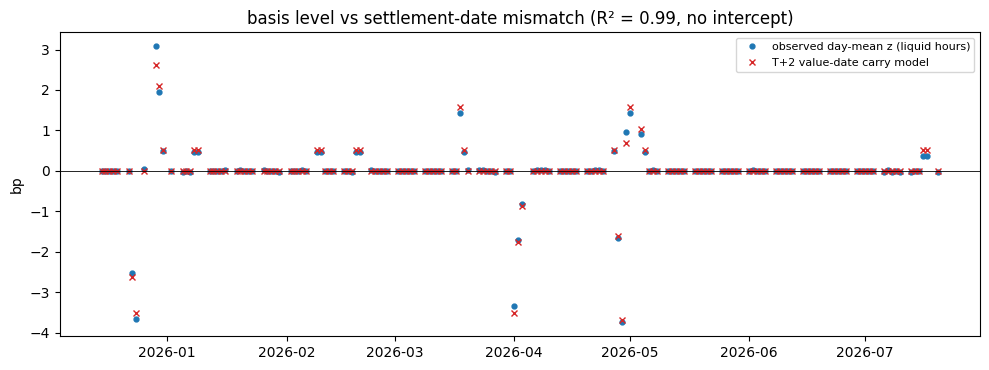

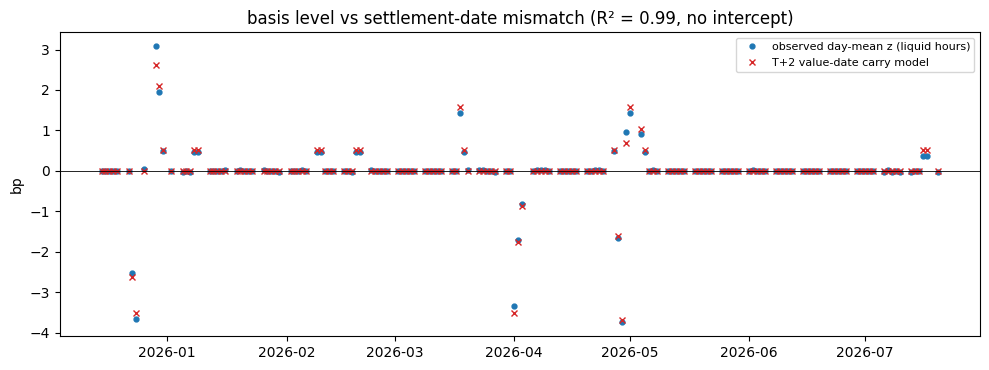

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
x = pd.to_datetime(act.index)
ax.plot(x, act.mean_bp, "o", ms=3.5, label="observed day-mean z (liquid hours)")
ax.plot(x, fit["pred_bp"], "x", ms=5, color="tab:red", label="T+2 value-date carry model")
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("bp"); ax.legend(fontsize=8)
ax.set_title(f"basis level vs settlement-date mismatch (R² = {fit['r2']:.2f}, no intercept)")
fig.tight_layout(); fig.savefig(OUTPUTS_DIR / "07_value_date_carry.png", dpi=130)
fig

## Takeaway

**The direction of leadership is robust; its size depends on the staleness control.** GG_cross is
0.652 [IQR 0.583, 0.727] on all grid bars, 0.587 fresh-only, and 0.570 [0.528, 0.616] in refresh
time. Refresh is lower on 126 of 151 paired days (sign test p = 2e-17), yet 86% of refresh windows
stay above 0.5. Report **0.57–0.65**: the LOCF grid roughly doubles the cross's lead over an even
split (0.15 vs 0.07), through the same mechanism that produced the three withdrawn effects.

**The session null depends on the clock.** On the grid nothing moves (H1–H5 Holm = 1). In refresh
time the cross's share rises through the day — 0.48 (TOK) → 0.54 → 0.58 → 0.59 → 0.61 (NY) — and
H3 has p = 0.005 (+0.050, CI [0.015, 0.092]): Holm 0.025 within the refresh family, **0.05 with
all ten tests on both clocks as one family** — borderline. TOK sits below LDN and NY with CIs
excluding zero, i.e. *opposite* to the pre-registered H1/H2 (so those one-sided tests do not
reject). H4 stays n.s. (+0.18 s). Refresh time is post-hoc and changes the estimand, and the
fresh-only grid shows no such gradient (05), so this is an unresolved, estimator-dependent pattern
— neither a confirmed migration nor a clean null. No session contrast is TOST-equivalent within
±0.05 after Holm on either clock (grid p_tost 0.47 / 0.43 / 0.13).

**Scope.** Inside 07–17 UTC, "TOK" is 07–08 UTC in Dec–Mar only and "NY" is the last 30–90 min
before 17:00, so session results describe the London trading day. Widening to 07–20 UTC gives NY
3.5–4.5 h and leaves the grid result unchanged (NY 0.679 vs 0.668; all hours 0.659 vs 0.652).

**The basis level is settlement-date carry.** Within a day z has sd 0.077 bp, but on 25 of 154
days its level shifts by 0.37–3.7 bp. All 25 are days where a holiday splits the legs' T+2 value
dates, with no false positives; a no-intercept carry model gives **R² = 0.993** and implies
r_USD − r_EUR ≈ 1.9% (with a constant the baseline is −0.005 bp, so the no-intercept restriction
holds). The per-window intercept absorbs it (GG 0.640 on shifted days vs 0.652). Christmas and New
Year's Day have no liquid-hours trading and are excluded by the `min_updates` guard.

**Still to do in 07 (Week-7 playbook):** GBP-triangle replication (EURUSD as the deep "cross" —
the prior flips), scheduled-news exclusion (`fxpd.calendar.news.news_mask`), and the full-family
multiplicity ledger (H1–H5, V1–V2, replications).